In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [36]:
!pip install -q kagglehub

In [37]:
import kagglehub

dataset_path = kagglehub.dataset_download("emmarex/plantdisease")

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/plantdisease


In [39]:
print("Dataset contents:")

for item in os.listdir(dataset_path):
    print(item)

Number of disease classes: 15

Class names:
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [40]:
data_dir = os.path.join(dataset_path, "PlantVillage")

print("Number of disease classes:", len(os.listdir(data_dir)))
print("\nClass names:")

for folder in sorted(os.listdir(data_dir)):
    print(folder)

Number of disease classes: 15

Class names:
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_YellowLeaf__Curl_Virus
Tomato__Tomato_mosaic_virus
Tomato_healthy


In [41]:
class_counts = {}

for folder in sorted(os.listdir(data_dir)):
    folder_path = os.path.join(data_dir, folder)
    if os.path.isdir(folder_path):
        class_counts[folder] = len([
            f for f in os.listdir(folder_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

for class_name, count in class_counts.items():
    print(class_name, ":", count)

print("\nTotal images:", sum(class_counts.values()))

Pepper__bell___Bacterial_spot : 997
Pepper__bell___healthy : 1478
Potato___Early_blight : 1000
Potato___Late_blight : 1000
Potato___healthy : 152
Tomato_Bacterial_spot : 2127
Tomato_Early_blight : 1000
Tomato_Late_blight : 1909
Tomato_Leaf_Mold : 952
Tomato_Septoria_leaf_spot : 1771
Tomato_Spider_mites_Two_spotted_spider_mite : 1676
Tomato__Target_Spot : 1404
Tomato__Tomato_YellowLeaf__Curl_Virus : 3208
Tomato__Tomato_mosaic_virus : 373
Tomato_healthy : 1591

Total images: 20638


**Visualize the number of images in each class**

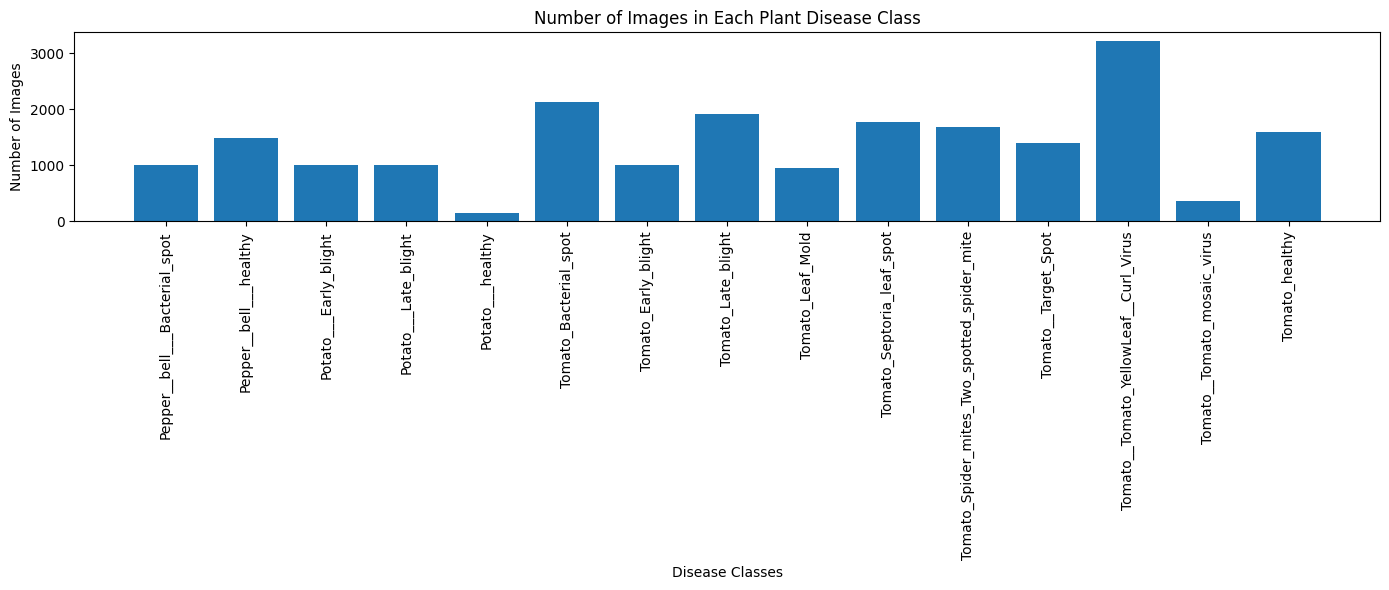

In [42]:
plt.figure(figsize=(14, 6))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Number of Images in Each Plant Disease Class")
plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Display sample leaf images**

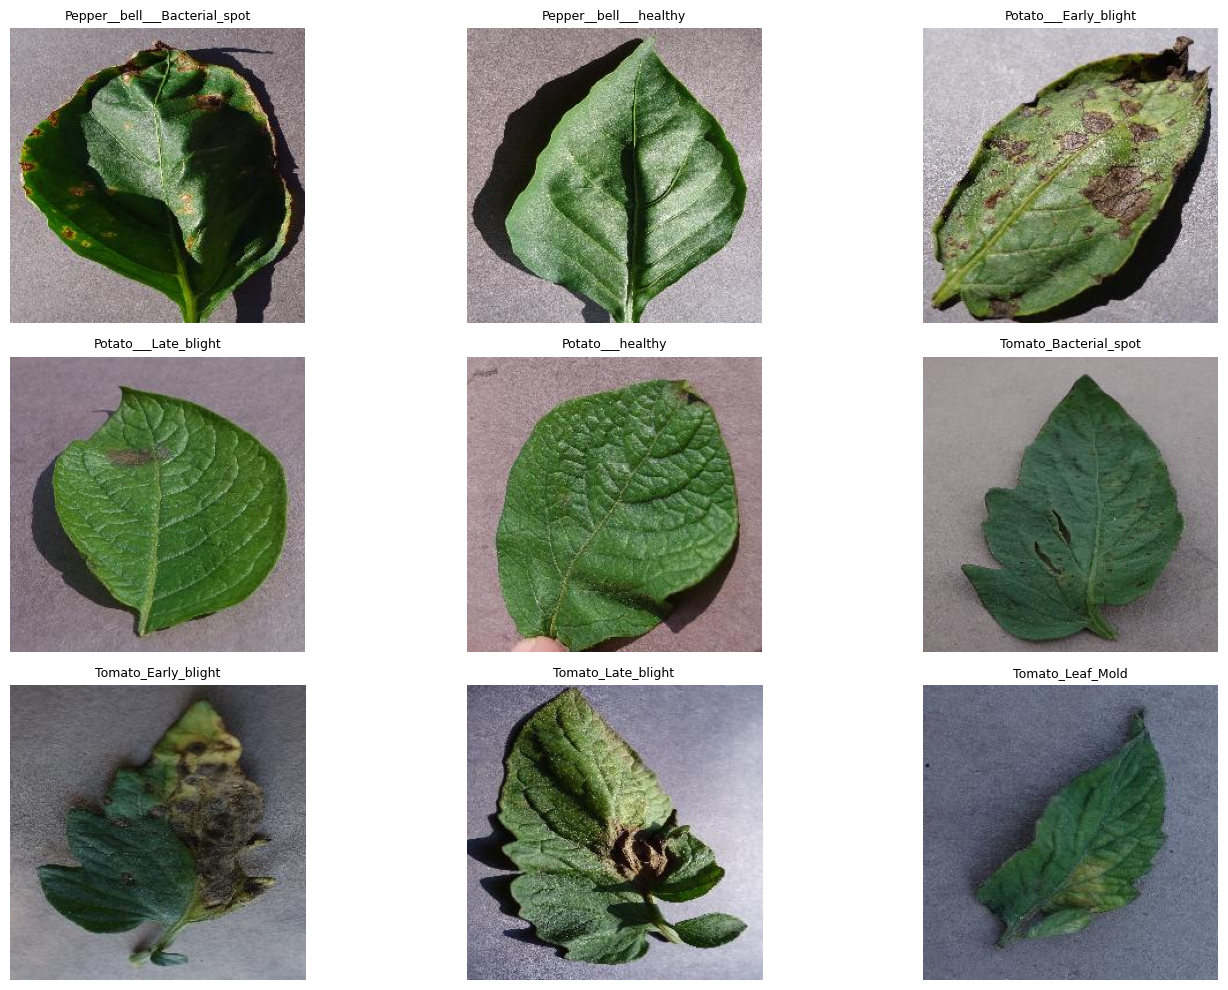

In [43]:
plt.figure(figsize=(15, 10))

for i, class_name in enumerate(sorted(os.listdir(data_dir))[:9]):
    folder_path = os.path.join(data_dir, class_name)
    image_name = os.listdir(folder_path)[0]

    img = Image.open(os.path.join(folder_path, image_name))

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

**Check image dimensions**

In [44]:
image_sizes = []

for class_name in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, class_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            img = Image.open(os.path.join(folder_path, filename))
            image_sizes.append(img.size)

print("Total images checked:", len(image_sizes))
print("Most common image dimensions:")

for size, count in Counter(image_sizes).most_common(10):
    print(size, ":", count)

Total images checked: 20638
Most common image dimensions:
(256, 256) : 20638


**Check for corrupted images**

In [45]:
valid_images = 0
corrupted_images = 0

for class_name in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, class_name)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            try:
                img = Image.open(os.path.join(folder_path, filename))
                img.verify()
                valid_images += 1
            except Exception:
                corrupted_images += 1

print("Valid images:", valid_images)
print("Corrupted images:", corrupted_images)

Valid images: 20638
Corrupted images: 0


**model training**

In [46]:
import tensorflow as tf

img_size = (128, 128)
batch_size = 32
seed = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_dataset.class_names

print("Number of classes:", len(class_names))
print("Class names:", class_names)

Found 20638 files belonging to 15 classes.
Using 16511 files for training.
Found 20638 files belonging to 15 classes.
Using 4127 files for validation.
Number of classes: 15
Class names: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


**Optimize the dataset**

In [47]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline optimized successfully!")

Dataset pipeline optimized successfully!


#Build the CNN model

In [48]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(len(class_names), activation='softmax')
])

print("CNN model created successfully!")

CNN model created successfully!


In [49]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [50]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,575 (12.61 MB)

 Trainable params: 3,306,575 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [51]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 598s 1s/step - accuracy: 0.4595 - loss: 1.6852 - val_accuracy: 0.7354 - val_loss: 0.8054
Epoch 2/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 622s 1s/step - accuracy: 0.6674 - loss: 1.0033 - val_accuracy: 0.7940 - val_loss: 0.6320
Epoch 3/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 600s 1s/step - accuracy: 0.7352 - loss: 0.7855 - val_accuracy: 0.8403 - val_loss: 0.4621
Epoch 4/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 663s 1s/step - accuracy: 0.7663 - loss: 0.6849 - val_accuracy: 0.8394 - val_loss: 0.4641
Epoch 5/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 586s 1s/step - accuracy: 0.7935 - loss: 0.5950 - val_accuracy: 0.8762 - val_loss: 0.3621
Epoch 6/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 583s 1s/step - accuracy: 0.8259 - loss: 0.4973 - val_accuracy: 0.8835 - val_loss: 0.3448
Epoch 7/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 587s 1s/step - accuracy: 0.8437 - loss: 0.4474 - val_accuracy: 0.8832 - val_loss: 0.3480
Epoch 8/10
516/516 ━━━━━━━━━━━━━━━━━━━━ 617s 1s/step - accuracy: 0.8611 - loss: 0.3963 - val_accu

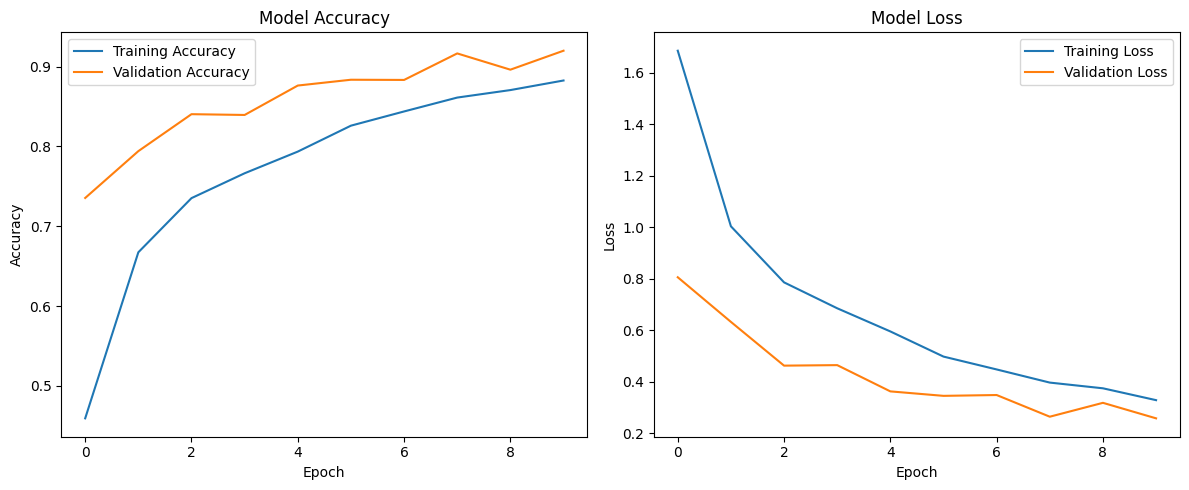

In [52]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [53]:
val_loss, val_accuracy = model.evaluate(validation_dataset)

print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

129/129 ━━━━━━━━━━━━━━━━━━━━ 42s 325ms/step - accuracy: 0.9198 - loss: 0.2574
Validation Loss: 0.2574
Validation Accuracy: 91.98 %


In [56]:
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in validation_dataset
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in validation_dataset
])

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.05      0.05      0.05       200
                     Pepper__bell___healthy       0.08      0.09      0.09       302
                      Potato___Early_blight       0.05      0.05      0.05       189
                       Potato___Late_blight       0.03      0.03      0.03       188
                           Potato___healthy       0.08      0.03      0.05        31
                      Tomato_Bacterial_spot       0.12      0.12      0.12       441
                        Tomato_Early_blight       0.06      0.07      0.07       191
                         Tomato_Late_blight       0.09      0.09      0.09       341
                           Tomato_Leaf_Mold       0.06      0.06      0.06       185
                  Tomato_Septoria_leaf_spot       0.08      0.08      0.08       392
Tomato_Spider_mites_Two_spotted_spider_mite       0.06      0.06

In [57]:
y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.89      0.92      0.91       200
                     Pepper__bell___healthy       0.93      0.98      0.95       302
                      Potato___Early_blight       0.94      0.97      0.96       189
                       Potato___Late_blight       0.90      0.82      0.86       188
                           Potato___healthy       1.00      0.39      0.56        31
                      Tomato_Bacterial_spot       0.96      0.97      0.96       441
                        Tomato_Early_blight       0.73      0.79      0.76       191
                         Tomato_Late_blight       0.86      0.84      0.85       341
                           Tomato_Leaf_Mold       0.82      0.91      0.86       185
                  Tomato_Septoria_leaf_spot       0.90      0.88      0.89       392
Tomato_Spider_mites_Two_spotted_spider_mite       0.94      0.95

**confusion matrix**

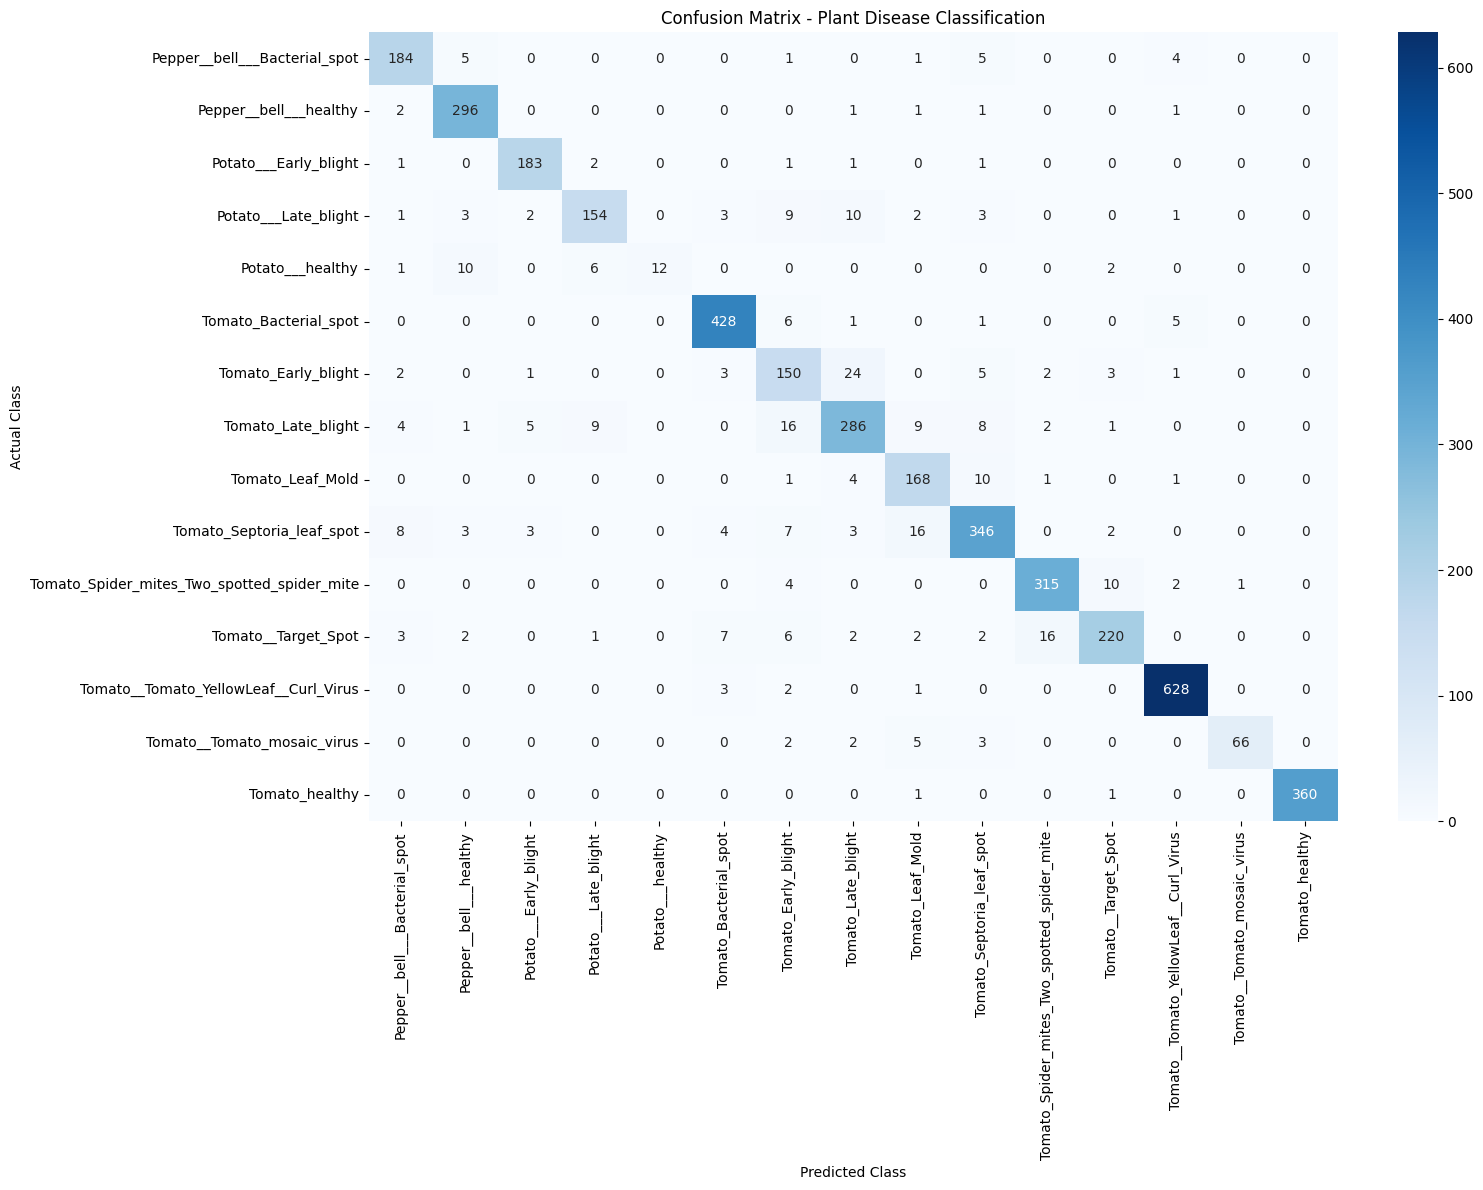

In [58]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Plant Disease Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Saving fb2c7e00-39a7-4be3-b8d1-b4c42c65e20e___RS_HL 9636.JPG to fb2c7e00-39a7-4be3-b8d1-b4c42c65e20e___RS_HL 9636.JPG


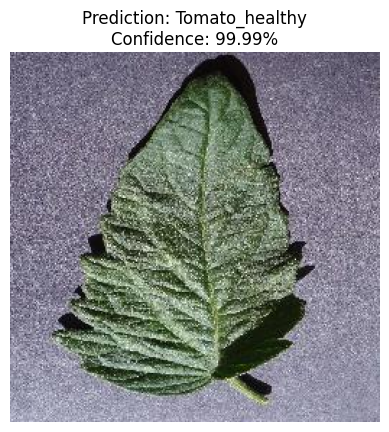

Predicted disease category: Tomato_healthy
Prediction confidence: 99.99 %


In [59]:
uploaded_image = files.upload()

for filename in uploaded_image.keys():
    img = Image.open(filename).convert("RGB")
    img_resized = img.resize((128, 128))

    img_array = np.array(img_resized)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
    plt.show()

    print("Predicted disease category:", predicted_class)
    print("Prediction confidence:", round(confidence, 2), "%")

In [60]:
model.save("plant_leaf_disease_model.keras")

print("Model saved successfully!")

Model saved successfully!


**class names**

In [61]:
with open("class_names.txt", "w") as file:
    for name in class_names:
        file.write(name + "\n")

print("Class names saved successfully!")

Class names saved successfully!


In [63]:
from google.colab import files
files.download("plant_leaf_disease_model.keras")
files.download("class_names.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
!pip install -q streamlit

In [65]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Plant Leaf Disease Classification",
    page_icon="🌿",
    layout="centered"
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("plant_leaf_disease_model.keras")

model = load_model()

with open("class_names.txt", "r") as file:
    class_names = [line.strip() for line in file.readlines()]

st.title("🌿 Plant Leaf Disease Classification")
st.write("Upload a plant leaf image to identify its disease category.")

uploaded_file = st.file_uploader(
    "Choose a leaf image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")

    st.image(image, caption="Uploaded Leaf Image", use_container_width=True)

    if st.button("Predict Disease"):
        resized_image = image.resize((128, 128))
        image_array = np.array(resized_image)
        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)

        predicted_index = np.argmax(predictions[0])
        predicted_class = class_names[predicted_index]
        confidence = predictions[0][predicted_index] * 100

        st.success(f"Predicted Category: {predicted_class}")
        st.metric("Prediction Confidence", f"{confidence:.2f}%")

Writing app.py


In [70]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

In [71]:
!sleep 5
!curl http://localhost:8501/_stcore/health

ok

In [72]:
from google.colab import output
output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>